Kmeans Projects 

In [34]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans


In [35]:
cust_df = pd.read_csv("1632560262896716.csv")
cust_df.head(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [36]:
cust_df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [37]:
# بهترین روش
gender_dummies = pd.get_dummies(cust_df['Gender'], prefix='Gender', drop_first=True)
cust_df = pd.concat([cust_df.drop('Gender', axis=1), gender_dummies], axis=1)

# حالا داده‌ها 0 و 1 هستند (و dot product معنی‌دار)

In [38]:
from sklearn.preprocessing import StandardScaler
X = cust_df.values[:,1:]
clus_dataset = StandardScaler().fit_transform(X)
clus_dataset 


array([[-1.42456879, -1.73899919, -0.43480148,  1.12815215],
       [-1.28103541, -1.73899919,  1.19570407,  1.12815215],
       [-1.3528021 , -1.70082976, -1.71591298, -0.88640526],
       [-1.13750203, -1.70082976,  1.04041783, -0.88640526],
       [-0.56336851, -1.66266033, -0.39597992, -0.88640526],
       [-1.20926872, -1.66266033,  1.00159627, -0.88640526],
       [-0.27630176, -1.62449091, -1.71591298, -0.88640526],
       [-1.13750203, -1.62449091,  1.70038436, -0.88640526],
       [ 1.80493225, -1.58632148, -1.83237767,  1.12815215],
       [-0.6351352 , -1.58632148,  0.84631002, -0.88640526],
       [ 2.02023231, -1.58632148, -1.4053405 ,  1.12815215],
       [-0.27630176, -1.58632148,  1.89449216, -0.88640526],
       [ 1.37433211, -1.54815205, -1.36651894, -0.88640526],
       [-1.06573534, -1.54815205,  1.04041783, -0.88640526],
       [-0.13276838, -1.54815205, -1.44416206,  1.12815215],
       [-1.20926872, -1.54815205,  1.11806095,  1.12815215],
       [-0.27630176, -1.

In [39]:
cluster_num = 4
K_means = KMeans(init="k-means++" , n_clusters=cluster_num , n_init=12)
K_means.fit(clus_dataset)
labels = K_means.labels_
labels

c:\Users\Legion\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


array([1, 1, 2, 0, 0, 0, 2, 0, 3, 0, 3, 0, 2, 0, 3, 1, 2, 1, 3, 0, 3, 1,
       2, 1, 2, 1, 2, 1, 2, 0, 3, 0, 3, 1, 2, 0, 2, 0, 2, 0, 2, 1, 3, 0,
       2, 0, 2, 0, 0, 0, 2, 1, 0, 3, 2, 3, 2, 3, 0, 3, 3, 1, 2, 2, 3, 1,
       2, 2, 1, 0, 3, 2, 2, 2, 3, 1, 2, 3, 0, 2, 3, 1, 3, 2, 0, 3, 2, 0,
       0, 2, 2, 1, 3, 2, 0, 1, 2, 0, 3, 1, 0, 2, 3, 1, 3, 0, 2, 3, 3, 3,
       3, 0, 2, 1, 0, 0, 2, 2, 2, 2, 1, 2, 0, 1, 0, 0, 3, 1, 3, 1, 3, 1,
       0, 0, 3, 0, 2, 1, 3, 0, 2, 1, 0, 0, 3, 1, 3, 0, 2, 1, 3, 1, 2, 0,
       2, 0, 3, 0, 3, 0, 2, 0, 3, 0, 3, 0, 3, 0, 2, 1, 3, 1, 3, 1, 2, 0,
       3, 1, 3, 1, 2, 0, 3, 0, 2, 1, 2, 1, 2, 0, 2, 0, 3, 0, 2, 0, 2, 1,
       3, 1], dtype=int32)

In [40]:
cust_df["Customer_groups"] = labels
cust_df.head(5)

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Male,Customer_groups
0,1,19,15,39,True,1
1,2,21,15,81,True,1
2,3,20,16,6,False,2
3,4,23,16,77,False,0
4,5,31,17,40,False,0


In [41]:
cust_df.groupby("Customer_groups").mean()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
Customer_groups,,,,,
0,100.210526,28.438596,59.666667,67.684211,0.0
1,103.375000,28.250000,62.000000,71.675000,1.0
2,94.818182,48.109091,58.818182,34.781818,0.0
3,104.958333,49.437500,62.416667,29.208333,1.0


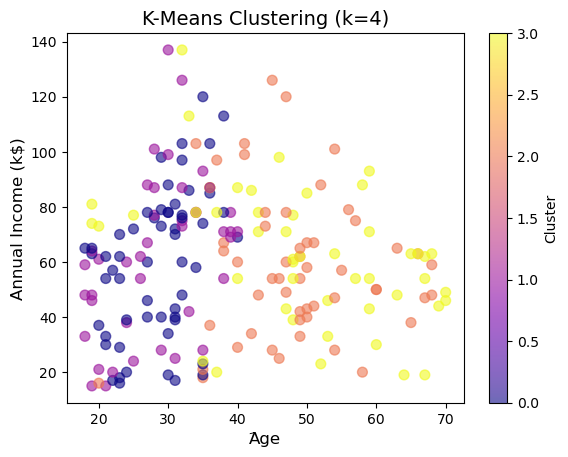

In [42]:
# استفاده از داده اصلی برای رسم (نه استاندارد شده)
x_original = cust_df['Age'].values
y_original = cust_df['Annual Income (k$)'].values

plt.scatter(x_original, y_original, s=50, c=labels, alpha=0.6, cmap='plasma')
plt.xlabel('َAge', fontsize=12)
plt.ylabel('Annual Income (k$)', fontsize=12)
plt.title(f'K-Means Clustering (k={cluster_num})', fontsize=14)
plt.colorbar(label='Cluster')
plt.show()

In [43]:
print("ابعاد X:", X.shape)
print("تعداد labels:", len(labels))

ابعاد X: (200, 4)
تعداد labels: 200
